# M1.3 分离变量与解析基准库 — 实验工作台（Lab）

> **与课件逐页对齐**：代码完全取自 `M1.3_演示网页.html`，从上到下依次运行。

**核心任务**：亲手运行方波 Fourier 级数截断与高频衰减，识别 9% 吉布斯（Gibbs）假过冲（F4 级数截断伪解）；运行一维弦驻波模态叠加与能量守恒检验；搭建属于你自己的解析基准库。


## ① 方波级数截断效应与时间衰减 (对应 Slide 09)

**物理直觉**：正弦波光滑圆润，方波直角断崖。光滑波硬拼阶跃在拐角处必然刹不住车，产生 9% 的吉布斯振铃过冲。
**代数揭秘**：由于半周期奇对称性，正弦内积积分中偶数项和奇数项相消，只有 $n \equiv 2 \pmod{4}$ 时系数才非零（$b_n = 8/(n\pi)$）！
**高频抹平**：随着时间推进，衰减因子 $e^{-\alpha(n\pi/L)^2 t}$ 随 $n^2$ 剧烈抹平高频毛刺。


t=0（纯 Gibbs 现象，无热扩散衰减）：
  N= 3  跳跃/边界外最大误差 = 0.7614
  N=11  跳跃/边界外最大误差 = 0.3280
  N=51  跳跃/边界外最大误差 = 0.0982

N=51，不同时刻 t（高频模态指数衰减）：
  t=0.000  全域温度峰值 = 1.1793
  t=0.001  全域温度峰值 = 1.0000
  t=0.010  全域温度峰值 = 0.8458
  t=0.050  全域温度峰值 = 0.1769


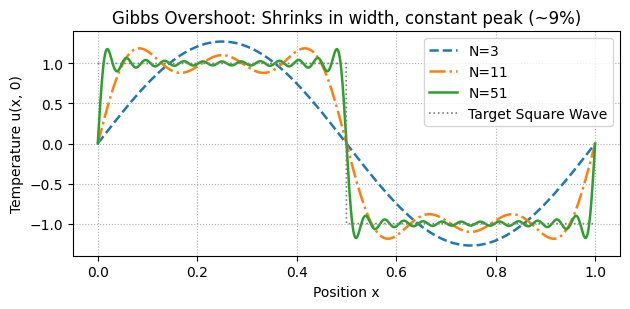

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

def square_wave_series(x, t, L=1.0, alpha=1.0, N=51):
    out = np.zeros_like(x, dtype=float)
    for n in range(1, N + 1):
        if n % 4 == 2:
            b = 8.0 / (n * np.pi)
            out += b * np.sin(n * np.pi * x / L) * np.exp(-alpha * (n * np.pi / L)**2 * t)
    return out

x = np.linspace(0, 1, 2001)
away = (np.abs(x - 0.5) > 0.03) & (x > 0.03) & (x < 0.97)
target = np.where(x < 0.5, 1.0, -1.0)

print("t=0（纯 Gibbs 现象，无热扩散衰减）：")
for N in (3, 11, 51):
    u = square_wave_series(x, t=0.0, N=N)
    err = np.max(np.abs(u[away] - target[away]))
    print(f"  N={N:2d}  跳跃/边界外最大误差 = {err:.4f}")

print("\nN=51，不同时刻 t（高频模态指数衰减）：")
for t in (0.0, 0.001, 0.01, 0.05):
    u = square_wave_series(x, t=t, N=51)
    print(f"  t={t:.3f}  全域温度峰值 = {np.max(np.abs(u)):.4f}")

plt.figure(figsize=(6.4, 3.2))
for N, ls in zip((3, 11, 51), ["--", "-.", "-"]):
    plt.plot(x, square_wave_series(x, 0.0, N=N), ls, lw=1.8, label=f"N={N}")
plt.plot(x, target, color="gray", lw=1.2, ls=":", label="Target Square Wave")
plt.xlabel("Position x"); plt.ylabel("Temperature u(x, 0)")
plt.title("Gibbs Overshoot: Shrinks in width, constant peak (~9%)")
plt.legend(loc="upper right"); plt.grid(True, ls=":")
plt.tight_layout(); plt.show()


## ② 弦驻波模态叠加与机械能守恒 (对应 Slide 10)

**物理直觉**：理想弦振动无能量耗散。每个正弦模态如同独立的单摆，各模态动能与势能交替转化，正交性保证互能为零，总能量千古守恒。
**代码验证**：计算三角形拨弦的初始傅里叶系数，并在 $t \in [0, 2.5]$ 个振动周期内计算总机械能的波动幅度。


各时刻机械能监测（动能 + 势能）：
  t=0.00s  Total Energy E = 2.352234
  t=0.30s  Total Energy E = 2.352256
  t=0.70s  Total Energy E = 2.352228
  t=1.30s  Total Energy E = 2.352256
  t=2.00s  Total Energy E = 2.352234


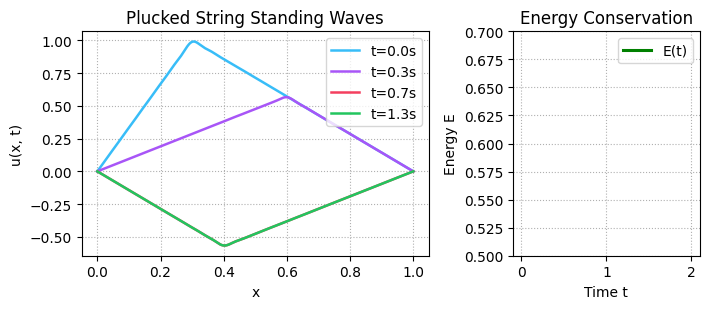

In [2]:
L, c, N = 1.0, 1.0, 40

def initial_shape(x):
    x0 = 0.3 * L
    return np.where(x < x0, x / x0, (L - x) / (L - x0))

trapz = getattr(np, "trapezoid", getattr(np, "trapz", None))

def a_coeffs(N):
    n = np.arange(1, N + 1)
    x = np.linspace(0, L, 4001)
    f = initial_shape(x)
    return np.array([2.0 / L * trapz(f * np.sin(k * np.pi * x / L), x) for k in n])

a = a_coeffs(N)
omega = np.arange(1, N + 1) * np.pi * c / L

def u_field(x, t):
    n = np.arange(1, N + 1)
    return (np.sin(np.outer(x, n) * np.pi / L) * np.cos(omega * t)) @ a

def energy(t, dt=1e-5, nx=4001):
    x = np.linspace(0, L, nx)
    ut = (u_field(x, t + dt) - u_field(x, t)) / dt
    ux = np.gradient(u_field(x, t), x)
    return 0.5 * trapz(ut**2 + c**2 * ux**2, x)

print("各时刻机械能监测（动能 + 势能）：")
for t in (0.0, 0.3, 0.7, 1.3, 2.0):
    print(f"  t={t:.2f}s  Total Energy E = {energy(t):.6f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7.2, 3.2), gridspec_kw={'width_ratios': [1.3, 0.7]})
x_fine = np.linspace(0, L, 1001)
for t_val, col in zip([0.0, 0.3, 0.7, 1.3], ['#38bdf8', '#a855f7', '#f43f5e', '#22c55e']):
    ax1.plot(x_fine, u_field(x_fine, t_val), color=col, lw=1.8, label=f"t={t_val:.1f}s")
ax1.set_xlabel("x"); ax1.set_ylabel("u(x, t)")
ax1.set_title("Plucked String Standing Waves"); ax1.legend(loc="upper right"); ax1.grid(True, ls=":")

t_span = np.linspace(0, 2.0, 11)
E_span = [energy(t) for t in t_span]
ax2.plot(t_span, E_span, 'g-', lw=2.2, label="E(t)")
ax2.set_ylim(0.5, 0.7)
ax2.set_xlabel("Time t"); ax2.set_ylabel("Energy E")
ax2.set_title("Energy Conservation"); ax2.legend(); ax2.grid(True, ls=":")

plt.tight_layout(); plt.show()


## ③ 总结：解析基准的两大质检意义

- **方波热扩散**：为瞬态求解器提供了高频抹平与 Gibbs 截断的标准答案；
- **弦驻波振动**：为时域波动算法提供了模态正交性与能量守恒的终极试金石。
